In [2]:
import sys
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))

import numpy as np, matplotlib.pyplot as plt
from data import get_splits
from metrics import evaluate, Timer
from forest import DecisionTree, RandomForest

d = get_splits()
Xtr, ytr, Xva, yva = d["X_train"], d["y_train"], d["X_val"], d["y_val"]
Xtr_b = (Xtr > 0.5).astype(np.float32)
Xva_b = (Xva > 0.5).astype(np.float32)
n_val = len(yva)
def se(acc):                       # sai số chuẩn của một phép đo accuracy trên n_val ảnh
    return np.sqrt(acc * (1 - acc) / n_val)

with Timer() as t:
    RandomForest(n_trees=1, max_depth=20).fit(Xtr_b, ytr)
print("1 cây:", round(t.seconds, 1), "s")

1 cây: 1.2 s


In [3]:
depths = [8, 12, 16, 20, 30]
resA = {}
for dep in depths:
    with Timer() as t:
        f = RandomForest(n_trees=30, max_depth=dep, seed=0).fit(Xtr_b, ytr)
    acc_k, acc_tree = f.staged_accuracy(Xva_b, yva)
    resA[dep] = dict(forest=acc_k[-1], tree=acc_tree.mean(),
                     train=(f.predict(Xtr_b) == ytr).mean(), sec=t.seconds)
    print(f"max_depth={dep:2d}: rừng val {acc_k[-1]*100:.2f}% | cây đơn trung bình {acc_tree.mean()*100:.2f}% "
          f"| train {resA[dep]['train']*100:.2f}% | fit {t.seconds:.0f}s")

best = max(resA[dp]["forest"] for dp in depths)
best_depth = min(dp for dp in depths if resA[dp]["forest"] >= best - se(best))
print(f"\naccuracy cao nhất {best*100:.2f}%, sai số chuẩn {se(best)*100:.2f} điểm")
print("độ sâu được chọn (nông nhất nằm trong 1 sai số chuẩn của tốt nhất):", best_depth)

max_depth= 8: rừng val 89.03% | cây đơn trung bình 64.26% | train 89.92% | fit 18s
max_depth=12: rừng val 94.00% | cây đơn trung bình 75.27% | train 97.15% | fit 23s
max_depth=16: rừng val 95.40% | cây đơn trung bình 78.29% | train 99.56% | fit 31s
max_depth=20: rừng val 95.63% | cây đơn trung bình 78.63% | train 99.89% | fit 36s
max_depth=30: rừng val 95.79% | cây đơn trung bình 78.59% | train 99.99% | fit 48s

accuracy cao nhất 95.79%, sai số chuẩn 0.20 điểm
độ sâu được chọn (nông nhất nằm trong 1 sai số chuẩn của tốt nhất): 20


huấn luyện 100 cây: 134s | cây đơn trung bình 78.70% (thấp nhất 77.27%, cao nhất 79.69%)
  1 cây: val 79.00%
  5 cây: val 90.22%
 10 cây: val 93.60%
 20 cây: val 95.21%
 30 cây: val 95.80%
 50 cây: val 96.03%
 75 cây: val 96.18%
100 cây: val 96.28%

số cây ít nhất mà accuracy nằm trong 1 sai số chuẩn của tốt nhất: 61


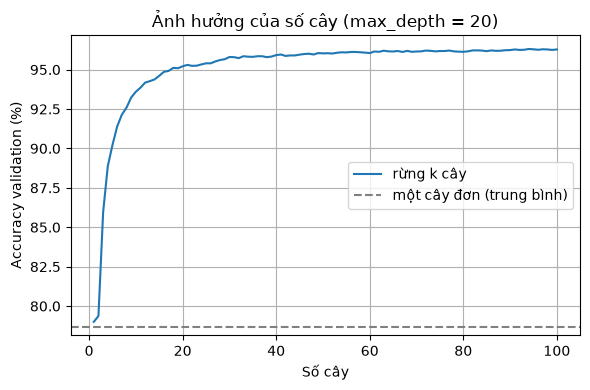

In [4]:
with Timer() as t:
    f = RandomForest(n_trees=100, max_depth=best_depth, seed=1).fit(Xtr_b, ytr)
acc_k, acc_tree = f.staged_accuracy(Xva_b, yva)
print(f"huấn luyện 100 cây: {t.seconds:.0f}s | cây đơn trung bình {acc_tree.mean()*100:.2f}% "
      f"(thấp nhất {acc_tree.min()*100:.2f}%, cao nhất {acc_tree.max()*100:.2f}%)")
for k in [1, 5, 10, 20, 30, 50, 75, 100]:
    print(f"{k:3d} cây: val {acc_k[k-1]*100:.2f}%")

best_k_acc = acc_k.max()
best_k = int(np.argmax(acc_k >= best_k_acc - se(best_k_acc))) + 1
print(f"\nsố cây ít nhất mà accuracy nằm trong 1 sai số chuẩn của tốt nhất: {best_k}")

plt.figure(figsize=(6, 4))
plt.plot(range(1, 101), acc_k * 100, label="rừng k cây")
plt.axhline(acc_tree.mean() * 100, ls="--", color="gray", label="một cây đơn (trung bình)")
plt.xlabel("Số cây"); plt.ylabel("Accuracy validation (%)"); plt.legend(); plt.grid(True)
plt.title(f"Ảnh hưởng của số cây (max_depth = {best_depth})")
plt.tight_layout()
plt.savefig(p / "report" / "forest_trees.png", dpi=150)
plt.show()

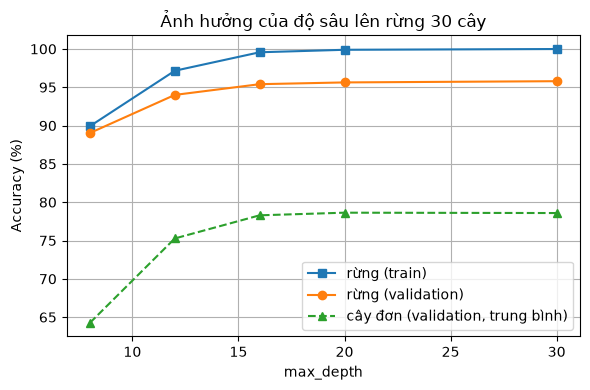

In [5]:
plt.figure(figsize=(6, 4))
plt.plot(depths, [resA[dp]["train"] * 100 for dp in depths], "s-", label="rừng (train)")
plt.plot(depths, [resA[dp]["forest"] * 100 for dp in depths], "o-", label="rừng (validation)")
plt.plot(depths, [resA[dp]["tree"] * 100 for dp in depths], "^--", label="cây đơn (validation, trung bình)")
plt.xlabel("max_depth"); plt.ylabel("Accuracy (%)"); plt.legend(); plt.grid(True)
plt.title("Ảnh hưởng của độ sâu lên rừng 30 cây")
plt.tight_layout()
plt.savefig(p / "report" / "forest_depth.png", dpi=150)
plt.show()

In [6]:
from sklearn.ensemble import RandomForestClassifier
sk = RandomForestClassifier(n_estimators=best_k, max_depth=best_depth, max_features=28,
                            random_state=0, n_jobs=-1).fit(Xtr_b, ytr)
mine = RandomForest(n_trees=best_k, max_depth=best_depth, seed=1).fit(Xtr_b, ytr)
print("sklearn (nhị phân):", (sk.predict(Xva_b) == yva).mean() * 100)
print("mình              :", (mine.predict(Xva_b) == yva).mean() * 100)

sk_raw = RandomForestClassifier(n_estimators=best_k, max_depth=best_depth, max_features=28,
                                random_state=0, n_jobs=-1).fit(Xtr, ytr)
print("sklearn (pixel gốc, chỉ để tham khảo):", (sk_raw.predict(Xva) == yva).mean() * 100)

sklearn (nhị phân): 96.1
mình              : 96.15
sklearn (pixel gốc, chỉ để tham khảo): 96.8


In [7]:
final = RandomForest(n_trees=best_k, max_depth=best_depth, seed=1).fit(Xtr_b, ytr)
p_tr, p_va = final.predict(Xtr_b), final.predict(Xva_b)
for name, y_true, y_pred in [("train", ytr, p_tr), ("val", yva, p_va)]:
    r = evaluate(y_true, y_pred)
    print(f"{name}: acc {r['accuracy']*100:.2f}% | P {r['precision_macro']*100:.2f}% | "
          f"R {r['recall_macro']*100:.2f}% | F1 {r['f1_macro']*100:.2f}%")

train: acc 99.91% | P 99.91% | R 99.91% | F1 99.91%
val: acc 96.15% | P 96.11% | R 96.11% | F1 96.11%


In [8]:
print(acc_k[60] * 100)     # kỳ vọng 96,15, trùng ô 6

96.15
